# 1. Load Libraries and data

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import math

from pathlib import Path
from rasterio.windows import from_bounds, Window

from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

%matplotlib inline

plt.rcParams.update({
    "font.size": 13,
    "figure.dpi": 120
})

ROOT = Path.cwd().resolve()

if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data"
OUTPUT_DIR = DATA_DIR / "derived"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "Emissivity": DATA_DIR / "Venus_Magellan_MicrowaveEmissivity_Global_4641m.tif",
    "Reflectivity": DATA_DIR / "Venus_Magellan_FresnelReflectivity_Global_4641m.tif",
    "RMS_Slope": DATA_DIR / "Venus_Magellan_MeterScaleSlope_Global_4641m.tif",
    "Topography": DATA_DIR / "Venus_Magellan_Topography_Global_4641m_v02.tif",
    "SAR_Brightness": DATA_DIR / "Venus_Magellan_C3-MDIR_Global_Mosaic_2025m.tif"
}

for name, path in FILES.items():
    if not path.exists():
        raise FileNotFoundError(path)

print("All five datasets found.")

All five datasets found.


# 2. Fibonaccii lat_long

In [33]:
# Global sampling parameters

N_SAMPLES = 50000
VENUS_RADIUS = 6051000.0


def fibonacci_sphere(n):

    i = np.arange(n)

    # Equally spaced in sin(latitude)
    z = 1 - 2 * (i + 0.5) / n

    lat = np.rad2deg(np.arcsin(z))

    # Golden-angle longitude
    golden_angle = np.pi * (3 - np.sqrt(5))

    lon = np.rad2deg(i * golden_angle)

    # Convert longitude to [-180, 180]
    lon = (lon + 180) % 360 - 180

    return pd.DataFrame({
        "Sample_ID": i,
        "Longitude": lon,
        "Latitude": lat
    })


df_global = fibonacci_sphere(N_SAMPLES)

display(df_global.head())
print("Total locations:", len(df_global))

,Sample_ID,Longitude,Latitude
0,0,0.000000,89.637629
1,1,137.507764,89.372353
2,2,-84.984472,89.189709
3,3,52.523292,89.041247
4,4,-169.968944,88.912873


Total locations: 50000


# 3. Visualize the sampling distribution

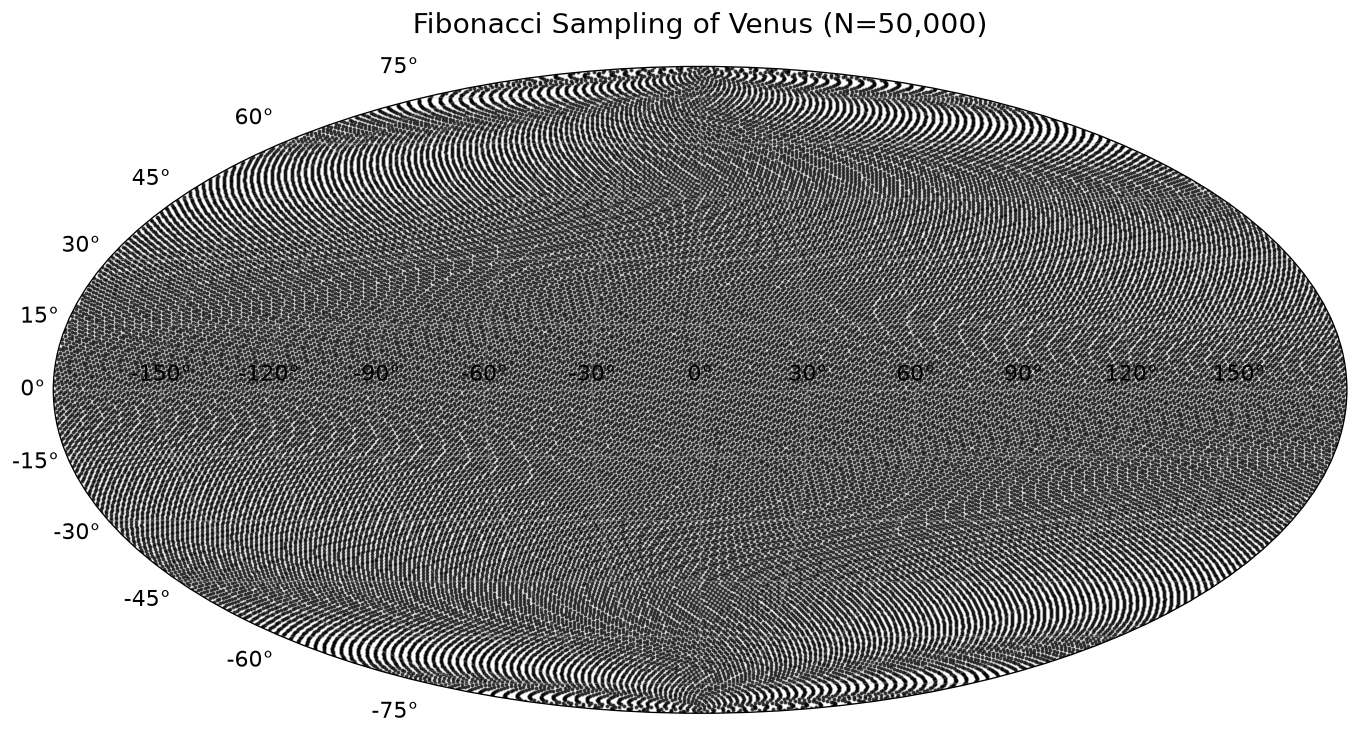

In [34]:
fig = plt.figure(figsize=(15, 7))

ax = fig.add_subplot(111, projection="mollweide")

ax.scatter(
    np.deg2rad(df_global["Longitude"]),
    np.deg2rad(df_global["Latitude"]),
    s=2,
    color="black",
    alpha=0.65,
    rasterized=True
)

ax.grid(alpha=0.3)
ax.set_title(
    f"Fibonacci Sampling of Venus (N={N_SAMPLES:,})",
    fontsize=17,
    pad=20
)

plt.show()

# Extract the Magellan measurements

## 4 — Extract a footprint-averaged value

In [35]:
# Approximate projected sampling window
FOOTPRINT_KM = 60

# Minimum valid coverage within each window
MIN_VALID_FRACTION = 0.70


def sample_footprint_means(
    dataset_name,
    locations,
    footprint_km=60,
    min_valid_fraction=0.70
):

    path = FILES[dataset_name]

    half_width = footprint_km * 1000 / 2

    output = np.full(
        len(locations),
        np.nan,
        dtype=np.float64
    )

    with rasterio.open(path) as src:

        scale = src.scales[0]
        offset = src.offsets[0]

        for i, (lon, lat) in enumerate(
            locations[["Longitude", "Latitude"]]
            .itertuples(index=False, name=None)
        ):

            # Geographic degrees -> Venus projected meters
            x = VENUS_RADIUS * np.deg2rad(lon)
            y = VENUS_RADIUS * np.deg2rad(lat)

            # Sampling window in projected coordinates
            w = from_bounds(
                left=x - half_width,
                bottom=y - half_width,
                right=x + half_width,
                top=y + half_width,
                transform=src.transform
            )

            # Expand to integer pixel boundaries
            col0 = math.floor(w.col_off)
            row0 = math.floor(w.row_off)

            col1 = math.ceil(w.col_off + w.width)
            row1 = math.ceil(w.row_off + w.height)

            # Skip windows crossing raster boundaries
            if (
                col0 < 0 or row0 < 0 or
                col1 > src.width or
                row1 > src.height
            ):
                continue

            window = Window(
                col_off=col0,
                row_off=row0,
                width=col1 - col0,
                height=row1 - row0
            )

            raw = src.read(
                1,
                window=window,
                masked=True
            ).astype(np.float64)

            raw = np.ma.filled(raw, np.nan)

            # Additional missing-data codes
            if dataset_name in [
                "Emissivity",
                "Reflectivity",
                "RMS_Slope"
            ]:
                raw[raw == 0] = np.nan

            elif dataset_name == "Topography":
                raw[raw == -32768] = np.nan

            valid = np.isfinite(raw)

            if valid.mean() < min_valid_fraction:
                continue

            raw_mean = np.nanmean(raw)

            # Use original PDS slope conversion
            if dataset_name == "RMS_Slope":
                value = (raw_mean - 1) / 10

            else:
                value = raw_mean * scale + offset

            output[i] = value

    return output

## 5 - extract all 5 datasetS

In [36]:
for name in FILES:

    print(f"Extracting {name}...")

    df_global[name] = sample_footprint_means(
        name,
        df_global,
        footprint_km=FOOTPRINT_KM,
        min_valid_fraction=MIN_VALID_FRACTION
    )

    n_valid = df_global[name].notna().sum()

    print(
        f"  Valid observations: "
        f"{n_valid:,}/{len(df_global):,}"
    )

print("\nExtraction complete.")

display(df_global.head())

Extracting Emissivity...
  Valid observations: 48,282/50,000
Extracting Reflectivity...
  Valid observations: 47,553/50,000
Extracting RMS_Slope...
  Valid observations: 48,505/50,000
Extracting Topography...
  Valid observations: 48,510/50,000
Extracting SAR_Brightness...
  Valid observations: 48,496/50,000

Extraction complete.


,Sample_ID,Longitude,Latitude,Emissivity,Reflectivity,RMS_Slope,Topography,SAR_Brightness
0,0,0.000000,89.637629,0.848500,NaN,NaN,NaN,132.805376
1,1,137.507764,89.372353,0.849096,NaN,NaN,NaN,NaN
2,2,-84.984472,89.189709,0.849322,NaN,NaN,NaN,121.347555
3,3,52.523292,89.041247,0.847025,NaN,NaN,NaN,NaN
4,4,-169.968944,88.912873,0.854314,NaN,NaN,NaN,137.386022


## Validate and save dataset

In [37]:
# Basic physical-range checks
# These are screening limits, not uncertainty filters.

physical_limits = {
    "Emissivity": (0, 1),
    "Reflectivity": (0, 1),
    "RMS_Slope": (0, 90)
}

for name, (low, high) in physical_limits.items():

    invalid = (
        (df_global[name] < low) |
        (df_global[name] > high)
    )

    print(f"{name}: {invalid.sum()} out-of-range values")

    df_global.loc[invalid, name] = np.nan


# Summary
display(
    df_global[
        list(FILES.keys())
    ].describe().round(4)
)

print("\nMissing data percentage:")

display(
    (
        df_global[list(FILES.keys())]
        .isna()
        .mean()
        .mul(100)
    ).round(2)
)

# Save complete dataset, retaining NaNs
df_global.to_csv(
    OUTPUT_DIR / "venus_fibonacci_10000.csv",
    index=False
)

Emissivity: 0 out-of-range values
Reflectivity: 0 out-of-range values
RMS_Slope: 0 out-of-range values


,Emissivity,Reflectivity,RMS_Slope,Topography,SAR_Brightness
count,48282.0000,47553.0000,48505.0000,48510.0000,48496.0000
mean,0.8451,0.1283,2.8542,885.1158,131.0970
std,0.0441,0.0548,1.1424,952.7700,19.4218
min,0.3366,0.0308,0.3214,-1197.5051,52.9834
25%,0.8325,0.0949,2.1026,289.1824,118.6392
50%,0.8500,0.1130,2.6750,682.8648,129.2219
75%,0.8671,0.1419,3.3735,1214.8291,141.5901
max,0.9655,0.7346,9.9531,10907.0918,219.2946



Missing data percentage:


Emissivity        3.44
Reflectivity      4.89
RMS_Slope         2.99
Topography        2.98
SAR_Brightness    3.01
dtype: float64

# Build the global three-dimensional clustering dataset

## 7 — Select features and standardize

In [38]:
CLUSTER_FEATURES = [
    "Emissivity",
    "Reflectivity",
    "RMS_Slope"
]

# Keep locations with complete clustering features
df_train = (
    df_global
    .dropna(subset=CLUSTER_FEATURES)
    .copy()
    .reset_index(drop=True)
)

X = df_train[CLUSTER_FEATURES].to_numpy()

scaler_global = StandardScaler()

X_scaled = scaler_global.fit_transform(X)

print("Clustering features:", CLUSTER_FEATURES)
print("Input matrix:", X_scaled.shape)

Clustering features: ['Emissivity', 'Reflectivity', 'RMS_Slope']
Input matrix: (46499, 3)


# Ward hierarchical clustering and the global dendrogram

## Cell 8 — Fit Ward hierarchical clustering

In [39]:
from scipy.cluster.hierarchy import linkage

print("Starting global Ward clustering...")

Z_global = linkage(
    X_scaled,
    method="ward",
    metric="euclidean",
    optimal_ordering=False
)

print("Ward clustering completed.")
print("Linkage matrix shape:", Z_global.shape)

Starting global Ward clustering...
Ward clustering completed.
Linkage matrix shape: (46498, 4)


## 9 — Plot the global dendrogram

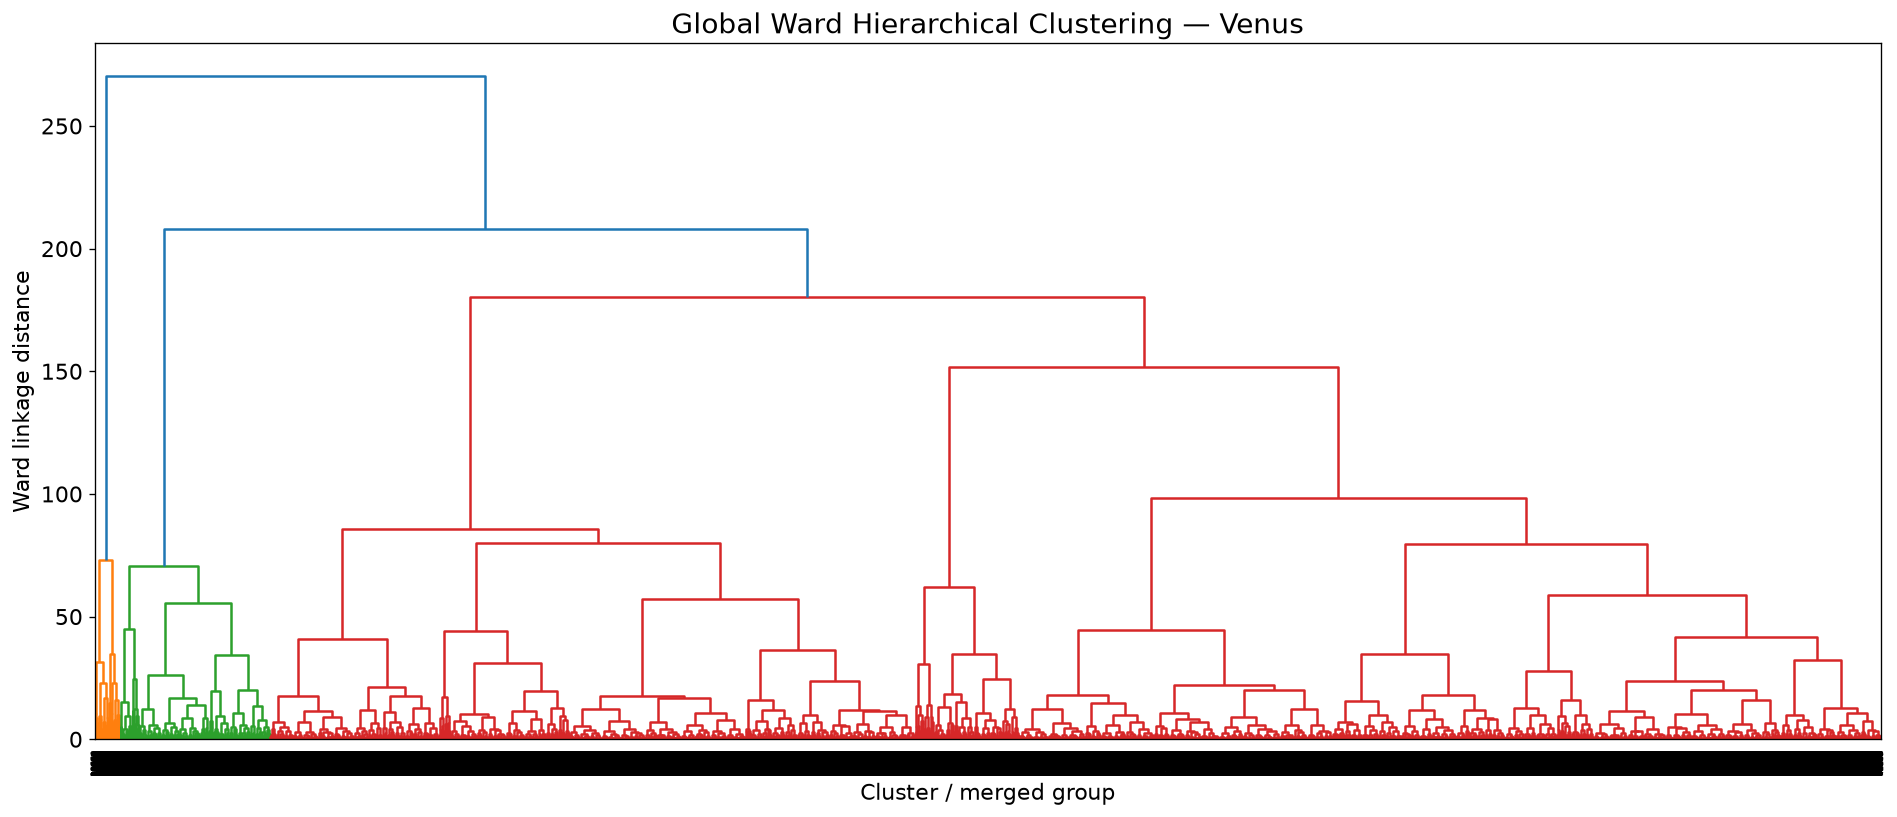

In [40]:
fig, ax = plt.subplots(figsize=(16, 7))

dendrogram(
    Z_global,
    truncate_mode="lastp",
    p=0,
    show_leaf_counts=True,
    show_contracted=True,
    ax=ax
)

ax.set_title(
    "Global Ward Hierarchical Clustering — Venus",
    fontsize=17
)

ax.set_xlabel("Cluster / merged group")
ax.set_ylabel("Ward linkage distance")

plt.tight_layout()
plt.show()

## 10 — Select your cluster count

In [41]:
# Cell 10 — Ward clustering using a distance threshold

from scipy.cluster.hierarchy import fcluster

# Set the Ward linkage distance threshold
CUT_DISTANCE = 50.0  # Example only; adjust based on your dendrogram

# Cut the dendrogram at the specified distance
labels_ward = fcluster(
    Z_global,
    t=CUT_DISTANCE,
    criterion="distance"
)

# Convert labels to 0-based indexing
labels_ward = labels_ward - 1

# Number of clusters identified automatically
K = len(np.unique(labels_ward))

df_train["Ward_Cluster"] = labels_ward

print(f"Cut distance: {CUT_DISTANCE:.2f}")
print(f"Number of clusters identified: {K}")

print("\nCluster populations:")
display(
    df_train["Ward_Cluster"]
    .value_counts()
    .sort_index()
)

Cut distance: 50.00
Number of clusters identified: 15

Cluster populations:


Ward_Cluster
0      379
1      298
2      486
3     1813
4     1598
5     4406
6     3384
7     4575
8     4439
9      469
10    2219
11    8158
12    4494
13    2312
14    7469
Name: count, dtype: int64

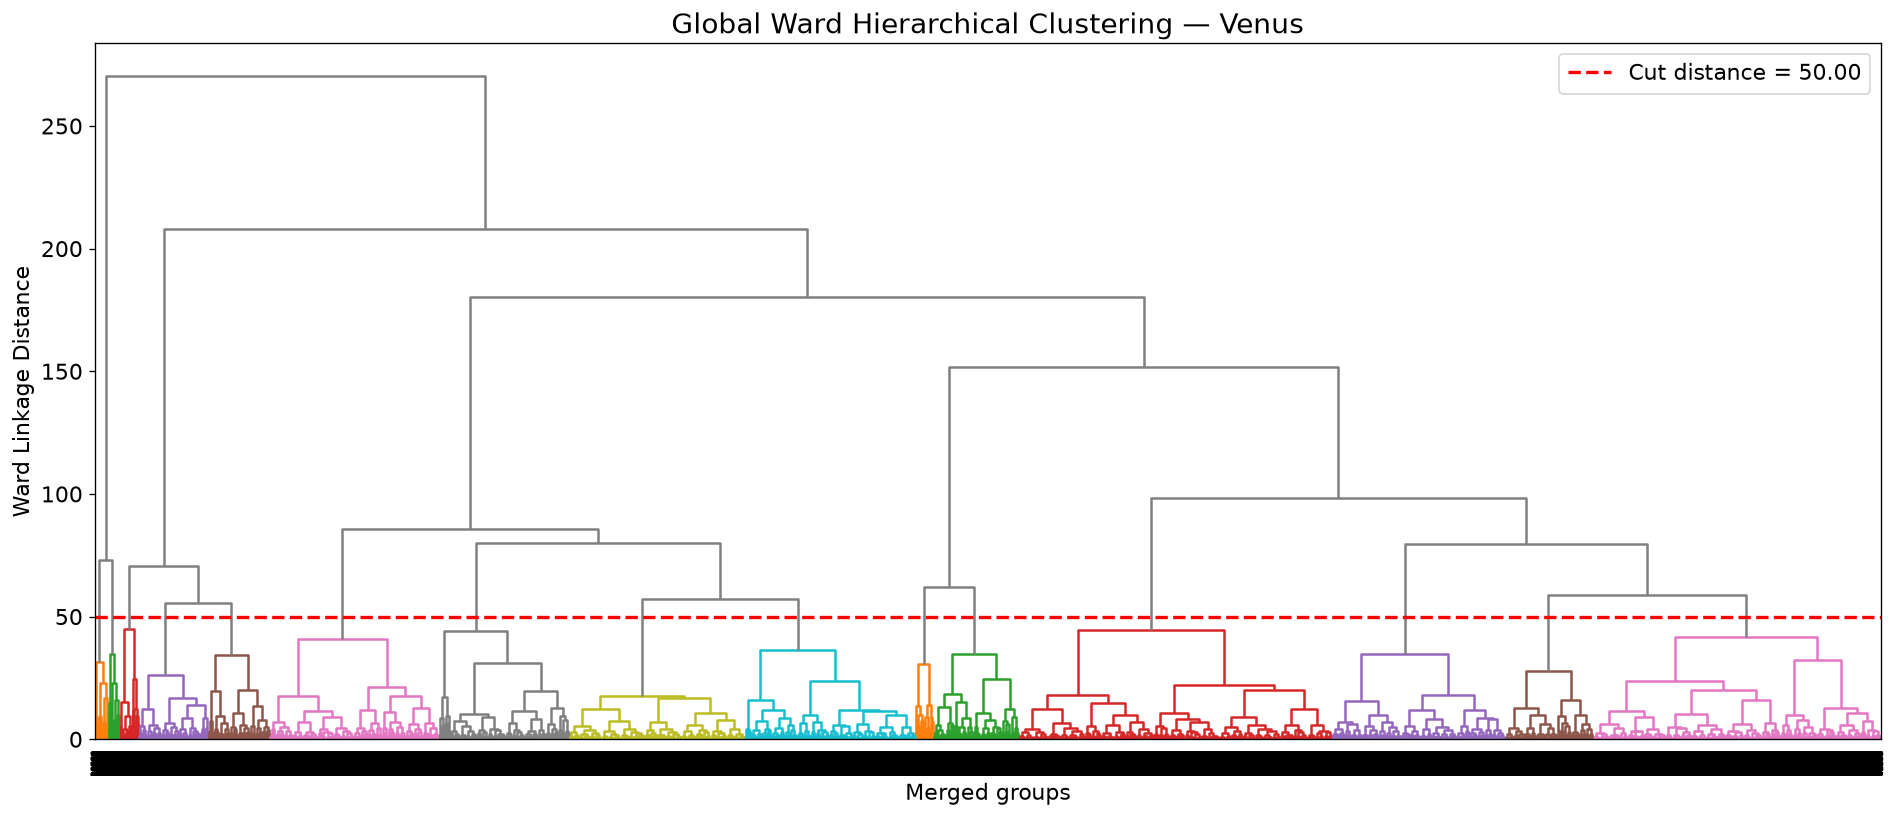

In [42]:
# Cell 9 — Global Ward dendrogram with distance cutoff

from scipy.cluster.hierarchy import dendrogram

# Set the threshold here
CUT_DISTANCE = 50.0  # Replace with your chosen merge distance

fig, ax = plt.subplots(figsize=(16, 7))

dendrogram(
    Z_global,
    truncate_mode="lastp",
    p=0,
    show_leaf_counts=True,
    show_contracted=True,
    color_threshold=CUT_DISTANCE,
    above_threshold_color="gray",
    ax=ax
)

# Show dendrogram cut
ax.axhline(
    y=CUT_DISTANCE,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Cut distance = {CUT_DISTANCE:.2f}"
)

ax.set_title(
    "Global Ward Hierarchical Clustering — Venus",
    fontsize=17
)

ax.set_xlabel("Merged groups")
ax.set_ylabel("Ward Linkage Distance")

ax.legend()

plt.tight_layout()
plt.show()

# Fit a global GMM using the same data

## 11 — Global GMM

In [43]:
gmm_global = GaussianMixture(
    n_components=K,
    covariance_type="full",
    n_init=10,
    reg_covar=1e-5,
    random_state=42,
    max_iter=500
)

labels_gmm = gmm_global.fit_predict(X_scaled)

df_train["GMM_Cluster"] = labels_gmm

df_train["GMM_Probability"] = (
    gmm_global.predict_proba(X_scaled).max(axis=1)
)

print("GMM cluster populations:")
display(
    df_train["GMM_Cluster"]
    .value_counts()
    .sort_index()
)

ari = adjusted_rand_score(
    labels_ward,
    labels_gmm
)

print(f"\nWard vs. GMM ARI: {ari:.3f}")

GMM cluster populations:


GMM_Cluster
0     2954
1     6715
2     3407
3      389
4      386
5     1760
6     7074
7      573
8     4937
9     1633
10    4279
11    7498
12    1292
13    2442
14    1160
Name: count, dtype: int64


Ward vs. GMM ARI: 0.366


# Generate the global cluster maps

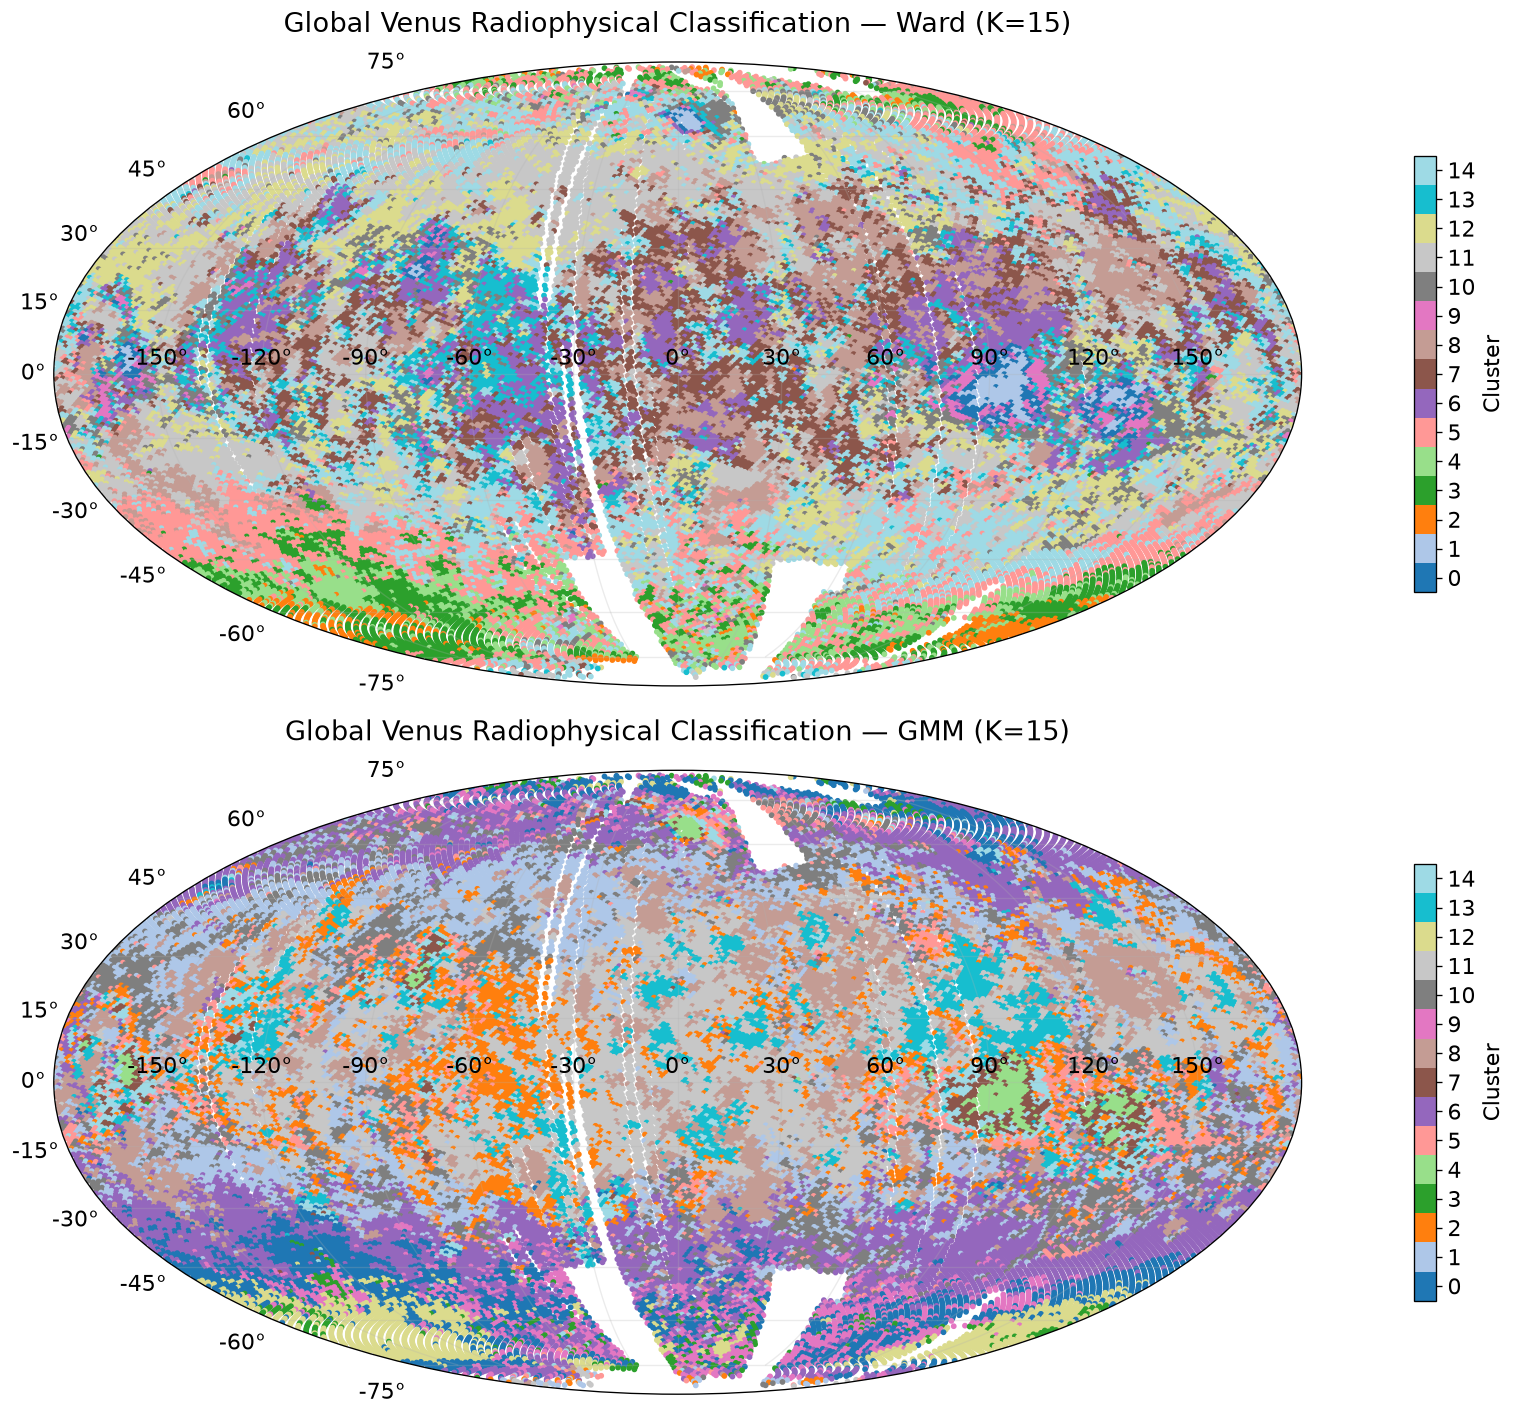

In [44]:
fig = plt.figure(figsize=(16, 12))

methods = [
    ("Ward", "Ward_Cluster"),
    ("GMM", "GMM_Cluster")
]

for i, (title, column) in enumerate(methods):

    ax = fig.add_subplot(
        2, 1, i + 1,
        projection="mollweide"
    )

    sc = ax.scatter(
        np.deg2rad(df_train["Longitude"]),
        np.deg2rad(df_train["Latitude"]),
        c=df_train[column],
        cmap=plt.get_cmap("tab20", K),
        vmin=-0.5,
        vmax=K-0.5,
        s=6,
        rasterized=True
    )

    ax.grid(alpha=0.25)

    ax.set_title(
        f"Global Venus Radiophysical Classification — {title} (K={K})",
        fontsize=16,
        pad=18
    )

    cb = fig.colorbar(
        sc,
        ax=ax,
        ticks=np.arange(K),
        shrink=0.7,
        pad=0.06
    )

    cb.set_label("Cluster")

plt.tight_layout()
plt.show()

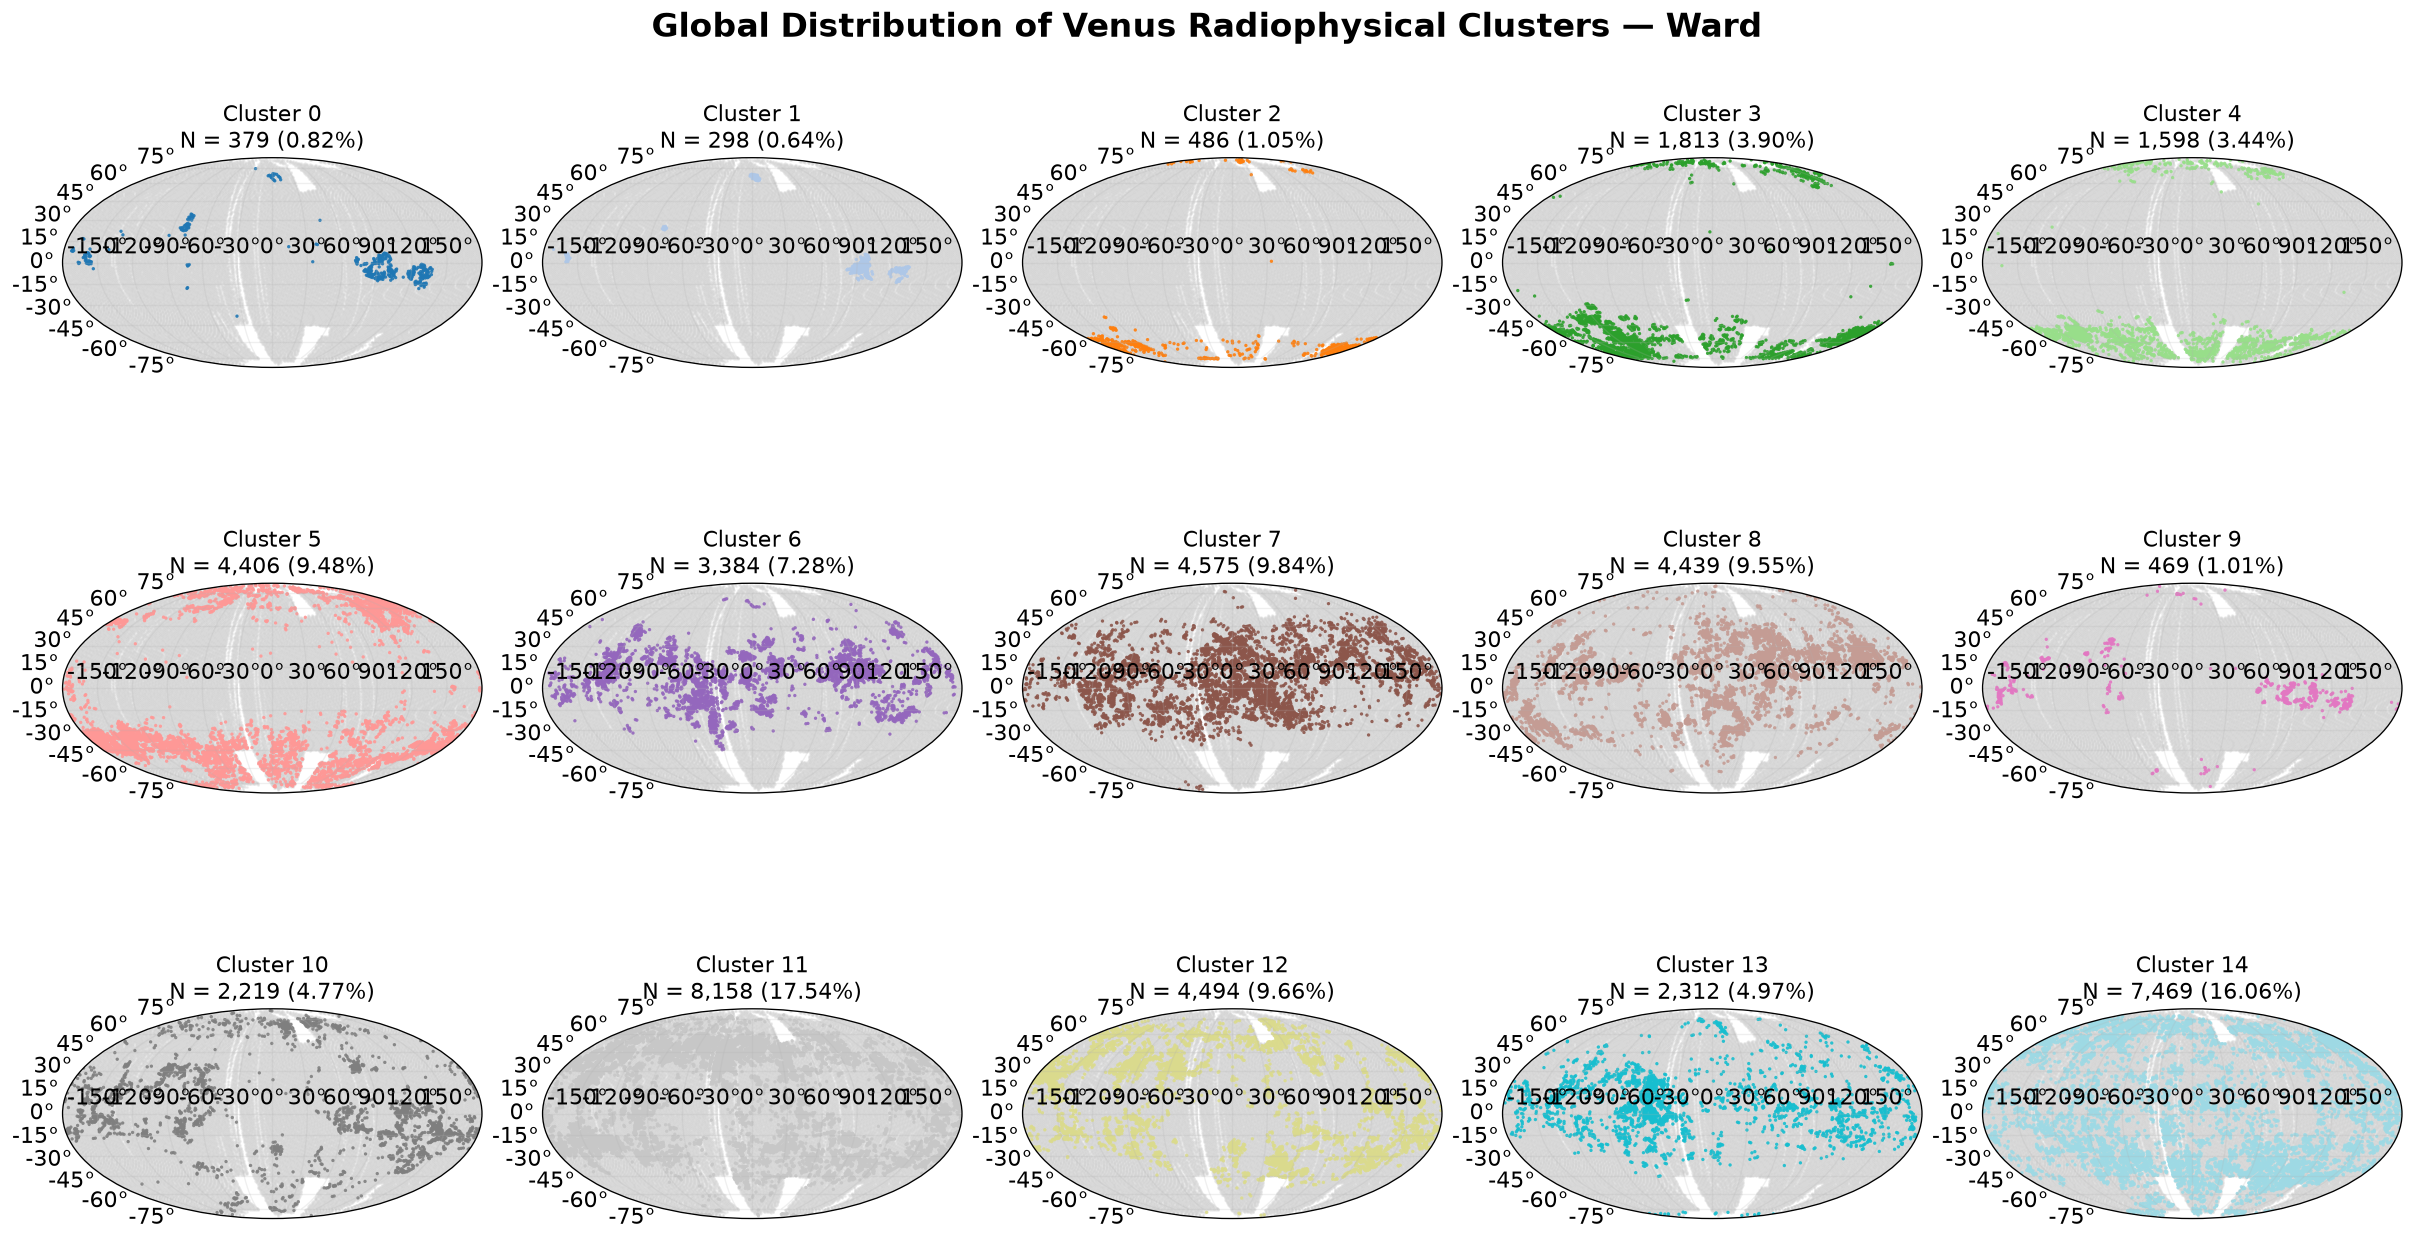

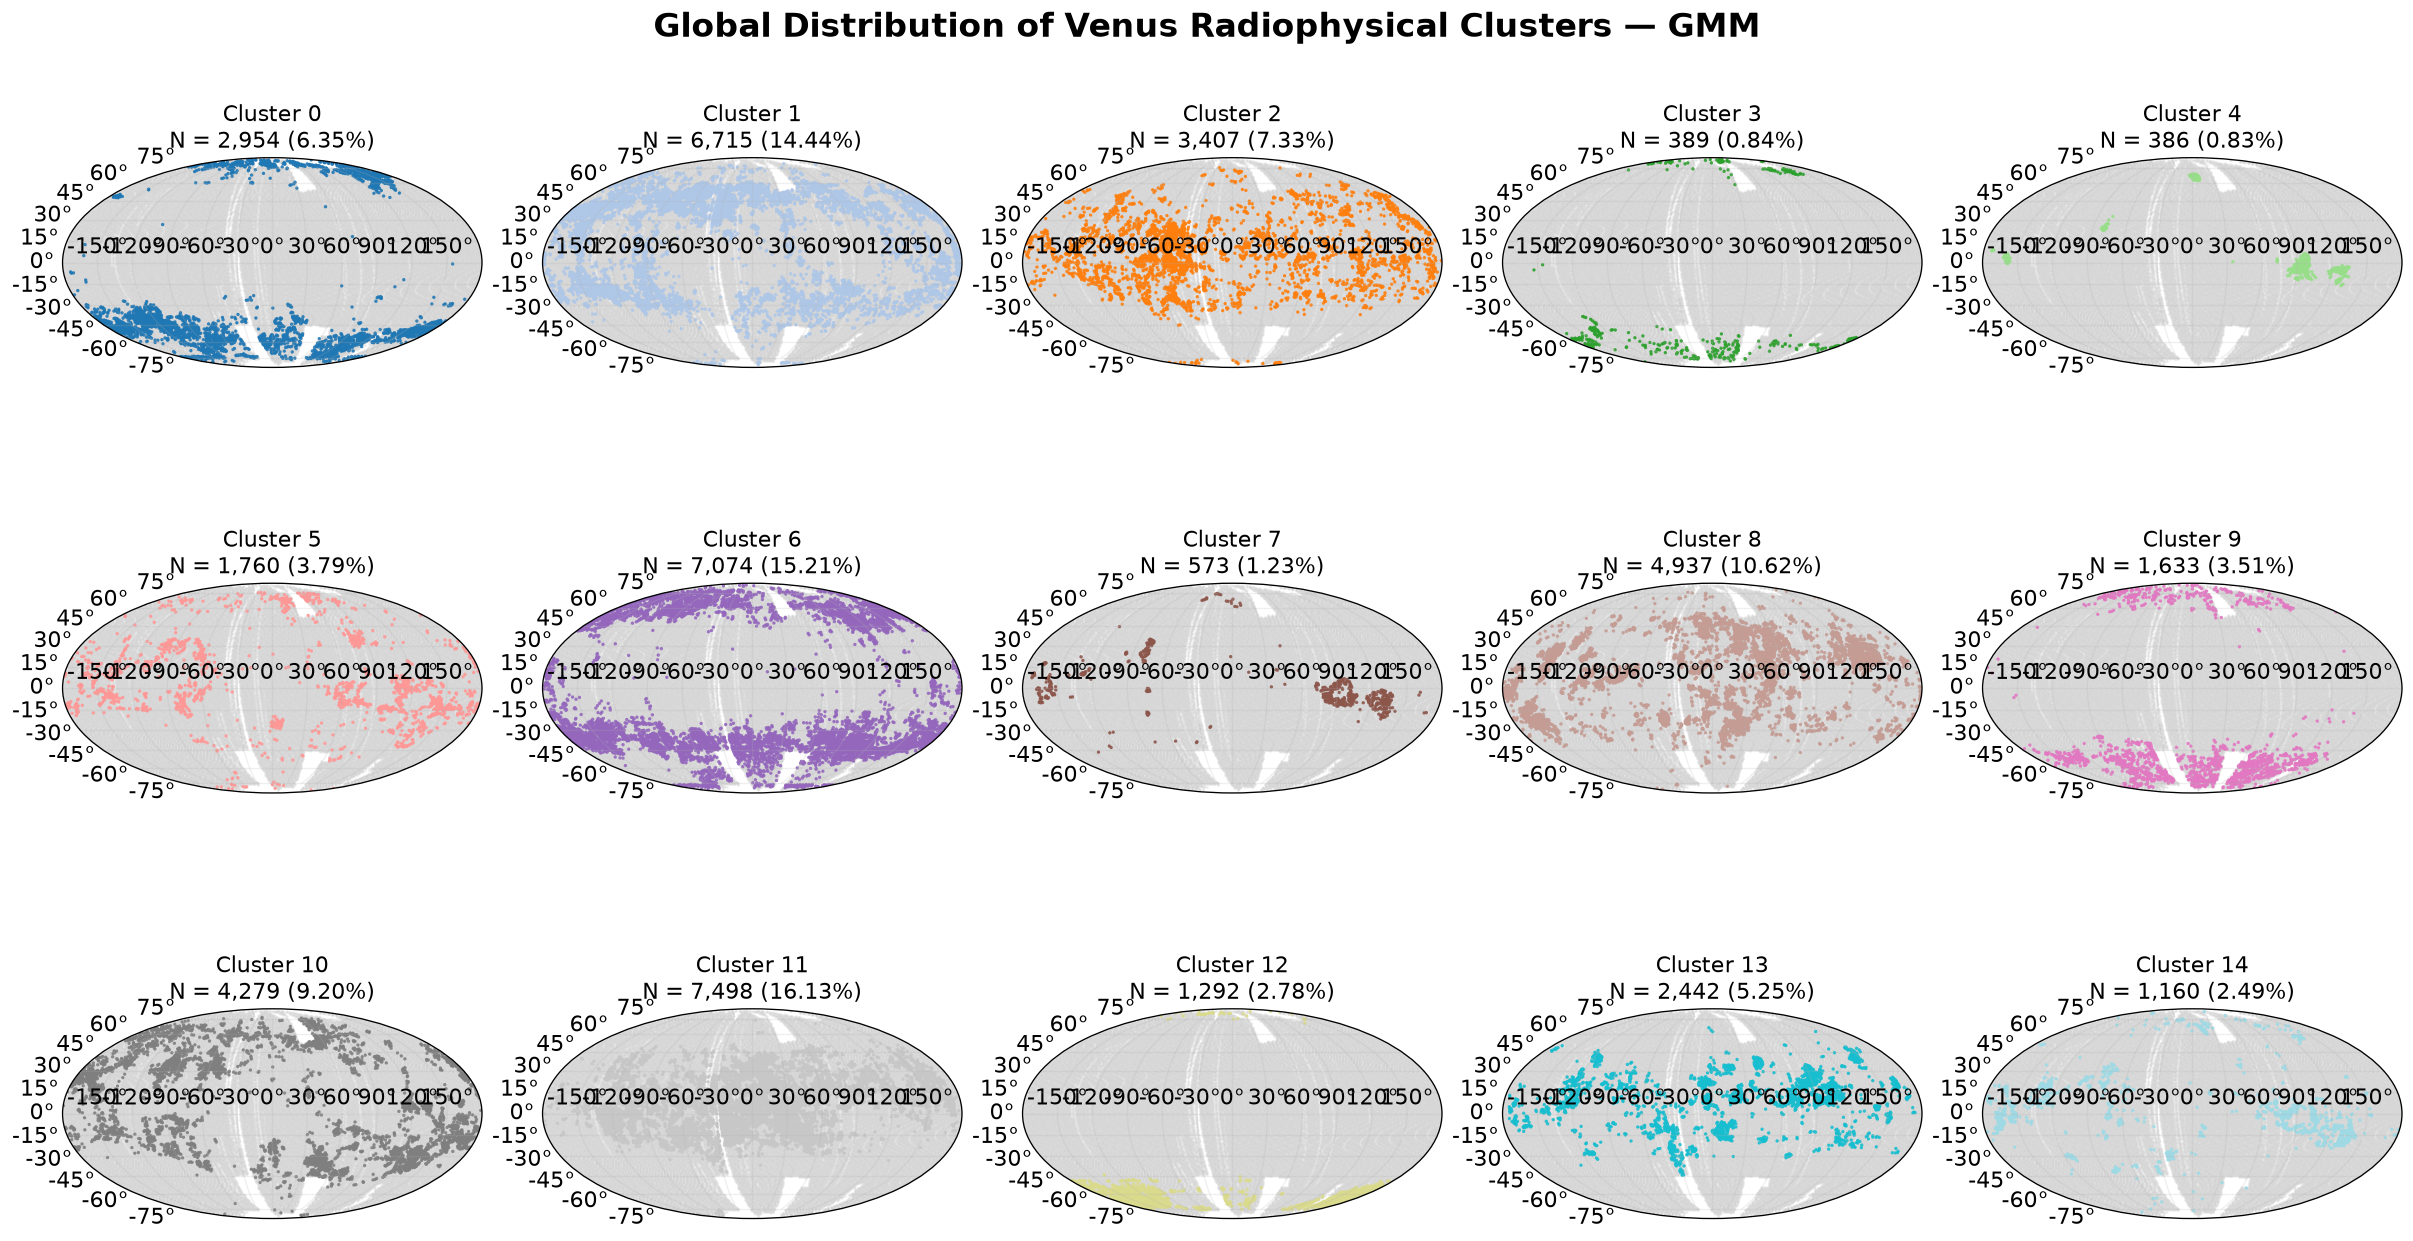

In [49]:
# Cell 19 — Plot each global cluster separately
# 15 maps for Ward and 15 maps for GMM

import numpy as np
import matplotlib.pyplot as plt

CLUSTER_METHODS = {
    "Ward": "Ward_Cluster",
    "GMM": "GMM_Cluster"
}

# Number of clusters
K = len(np.unique(df_train["Ward_Cluster"]))

# Geographic coordinates in radians
lon = np.deg2rad(df_train["Longitude"].to_numpy())
lat = np.deg2rad(df_train["Latitude"].to_numpy())

# Colors for individual clusters
colors = plt.get_cmap("tab20", K)


for method_name, cluster_col in CLUSTER_METHODS.items():

    labels = df_train[cluster_col].to_numpy()

    fig, axes = plt.subplots(
        3, 5,
        figsize=(20, 11),
        subplot_kw={"projection": "mollweide"},
        constrained_layout=True
    )

    axes = axes.flatten()

    for k in range(K):

        ax = axes[k]

        mask = labels == k

        # Background: all global sampled locations
        ax.scatter(
            lon,
            lat,
            s=0.5,
            color="lightgray",
            alpha=0.3,
            rasterized=True
        )

        # Highlight selected cluster
        ax.scatter(
            lon[mask],
            lat[mask],
            s=4,
            color=colors(k),
            alpha=0.9,
            edgecolors="none",
            rasterized=True
        )

        # Cluster statistics
        n = mask.sum()
        percentage = 100 * n / len(labels)

        ax.set_title(
            f"Cluster {k}\n"
            f"N = {n:,} ({percentage:.2f}%)",
            fontsize=13
        )

        ax.grid(alpha=0.2)

    # Hide unused panels if K < 15
    for ax in axes[K:]:
        ax.set_visible(False)

    fig.suptitle(
        f"Global Distribution of Venus Radiophysical Clusters — {method_name}",
        fontsize=20,
        fontweight="bold"
    )

    plt.show()

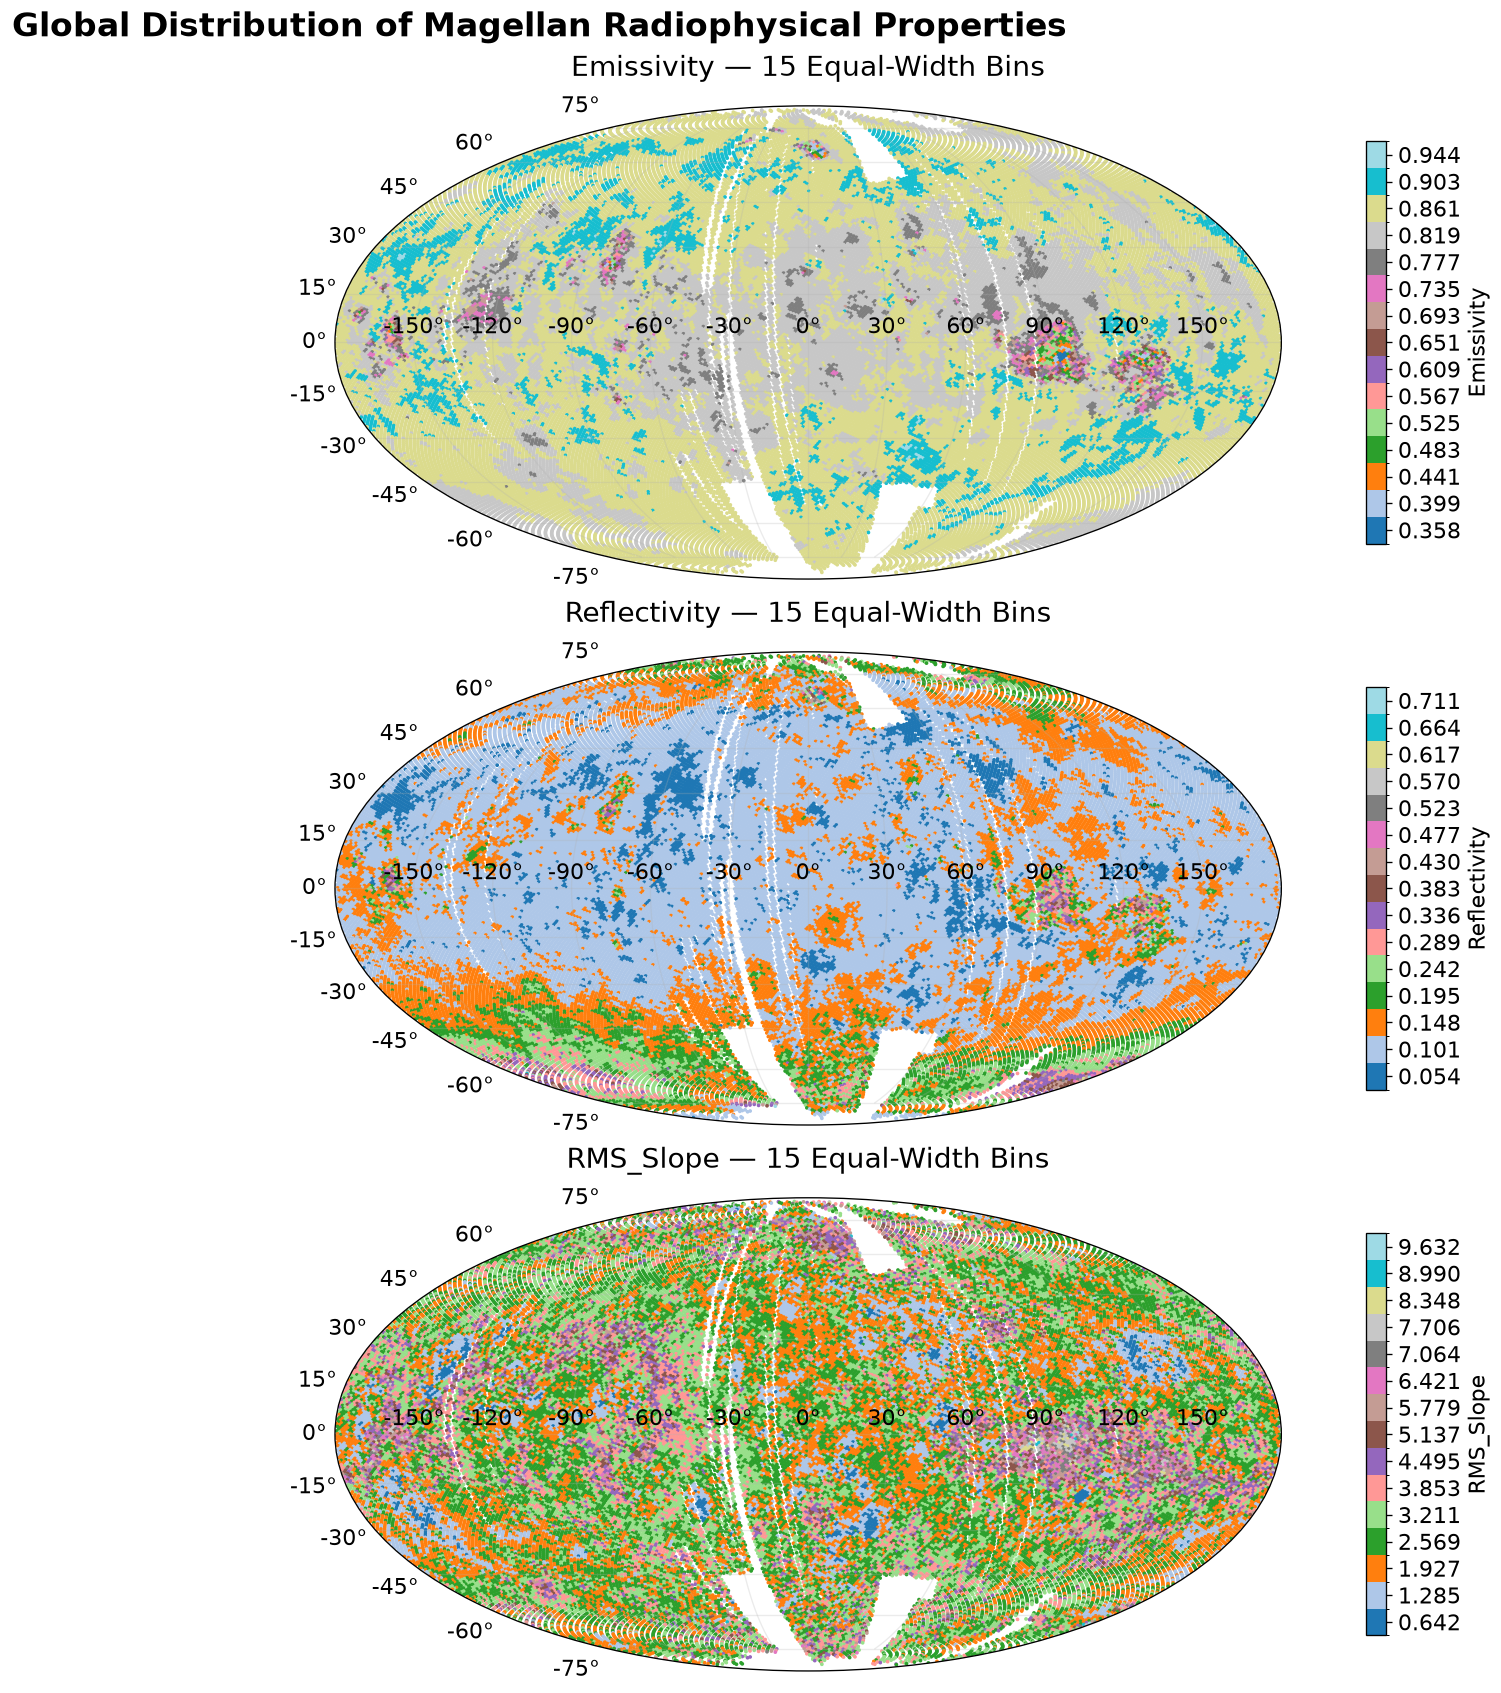

In [50]:
# Cell 19 — Global feature maps with 15 discrete color bins

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm

# Features used in global clustering
FEATURES_TO_PLOT = [
    "Emissivity",
    "Reflectivity",
    "RMS_Slope"
]

N_BINS = 15

# Discrete categorical colors, similar to cluster maps
cmap = plt.get_cmap("tab20", N_BINS)

# Coordinates in radians
lon = np.deg2rad(df_train["Longitude"].to_numpy())
lat = np.deg2rad(df_train["Latitude"].to_numpy())

fig, axes = plt.subplots(
    len(FEATURES_TO_PLOT), 1,
    figsize=(16, 14),
    subplot_kw={"projection": "mollweide"},
    constrained_layout=True
)

for ax, feature in zip(axes, FEATURES_TO_PLOT):

    values = df_train[feature].to_numpy()

    valid = np.isfinite(values)

    # Minimum and maximum values
    vmin = np.min(values[valid])
    vmax = np.max(values[valid])

    # Divide numerical range into 15 equal-width bins
    bin_edges = np.linspace(
        vmin,
        vmax,
        N_BINS + 1
    )

    # Discrete color normalization
    norm = BoundaryNorm(
        bin_edges,
        ncolors=N_BINS,
        clip=True
    )

    sc = ax.scatter(
        lon[valid],
        lat[valid],
        c=values[valid],
        cmap=cmap,
        norm=norm,
        s=5,
        linewidths=0,
        rasterized=True
    )

    # Colorbar with actual feature values
    bin_centers = (
        bin_edges[:-1] + bin_edges[1:]
    ) / 2

    cb = fig.colorbar(
        sc,
        ax=ax,
        ticks=bin_centers,
        boundaries=bin_edges,
        spacing="uniform",
        shrink=0.85,
        pad=0.05
    )

    cb.set_ticklabels([
        f"{v:.3f}" for v in bin_centers
    ])

    cb.set_label(feature)

    ax.set_title(
        f"{feature} — 15 Equal-Width Bins",
        fontsize=17,
        pad=18
    )

    ax.grid(alpha=0.25)

plt.suptitle(
    "Global Distribution of Magellan Radiophysical Properties",
    fontsize=20,
    fontweight="bold"
)

plt.show()

In [51]:
FEATURES_TO_PLOT = [
    "Emissivity",
    "Reflectivity",
    "RMS_Slope"
]

N_BINS = 15

for feature in FEATURES_TO_PLOT:

    values = df_train[feature].dropna().to_numpy()

    counts, edges = np.histogram(
        values,
        bins=N_BINS
    )

    summary = pd.DataFrame({
        "Bin": np.arange(1, N_BINS + 1),
        "Minimum": edges[:-1],
        "Maximum": edges[1:],
        "N": counts,
        "Percent": 100 * counts / counts.sum()
    })

    print(f"\n{feature}")
    display(summary.round(4))


Emissivity


,Bin,Minimum,Maximum,N,Percent
0,1,0.3366,0.3785,14,0.0301
1,2,0.3785,0.4204,34,0.0731
2,3,0.4204,0.4624,44,0.0946
3,4,0.4624,0.5043,74,0.1591
4,5,0.5043,0.5462,92,0.1979
5,6,0.5462,0.5881,98,0.2108
6,7,0.5881,0.6301,95,0.2043
7,8,0.6301,0.6720,121,0.2602
8,9,0.6720,0.7139,162,0.3484
9,10,0.7139,0.7558,281,0.6043



Reflectivity


,Bin,Minimum,Maximum,N,Percent
0,1,0.0308,0.0777,3119,6.7077
1,2,0.0777,0.1247,25878,55.6528
2,3,0.1247,0.1716,10720,23.0543
3,4,0.1716,0.2185,3417,7.3485
4,5,0.2185,0.2654,1836,3.9485
5,6,0.2654,0.3123,814,1.7506
6,7,0.3123,0.3593,413,0.8882
7,8,0.3593,0.4062,162,0.3484
8,9,0.4062,0.4531,80,0.1720
9,10,0.4531,0.5000,25,0.0538



RMS_Slope


,Bin,Minimum,Maximum,N,Percent
0,1,0.3214,0.9635,569,1.2237
1,2,0.9635,1.6056,4043,8.6948
2,3,1.6056,2.2478,9956,21.4112
3,4,2.2478,2.8899,13104,28.1813
4,5,2.8899,3.5320,9116,19.6047
5,6,3.5320,4.1741,4583,9.8561
6,7,4.1741,4.8162,2298,4.9420
7,8,4.8162,5.4583,1221,2.6259
8,9,5.4583,6.1004,720,1.5484
9,10,6.1004,6.7425,427,0.9183


# Characterize global population

In [45]:
PHYSICAL_FEATURES = [
    "Emissivity",
    "Reflectivity",
    "RMS_Slope",
    "Topography"
]

for method in ["Ward_Cluster", "GMM_Cluster"]:

    print(f"\n{'=' * 55}")
    print(method)
    print("=" * 55)

    summary = (
        df_train.groupby(method)[PHYSICAL_FEATURES]
        .agg(["median", "std"])
    )

    display(summary.round(4))


Ward_Cluster


Emissivity         Reflectivity         RMS_Slope          \
                 median     std       median     std    median     std   
Ward_Cluster                                                             
0                0.6416  0.0492       0.2427  0.0590    5.2556  1.3878   
1                0.4974  0.0599       0.3398  0.0878    6.4291  1.2667   
2                0.8327  0.0155       0.3357  0.0612    3.2028  1.8329   
3                0.8389  0.0153       0.2251  0.0303    2.1736  0.4344   
4                0.8511  0.0150       0.2378  0.0383    3.5686  0.7140   
5                0.8495  0.0138       0.1651  0.0210    2.2347  0.5842   
6                0.8059  0.0253       0.1236  0.0288    2.8508  0.5310   
7                0.8317  0.0108       0.1046  0.0126    2.3158  0.2622   
8                0.8325  0.0202       0.1210  0.0208    1.4046  0.3311   
9                0.7936  0.0478       0.1421  0.0417    6.4214  0.8938   
10               0.8741  0.0252       0.0968  0.0289    5.0648  0.6314   
11               0.8653  0.0127       0.0977  0.0146    2.2306  0.4737   
12               0.8838  0.0132       0.0811  0.0145    3.5209  0.5175   
13               0.8383  0.0192       0.0981  0.0210    3.8459  0.4013   
14               0.8558  0.0141       0.1185  0.0220    2.9622  0.4234   

             Topography             
                 median        std  
Ward_Cluster                        
0             4006.2347   823.7520  
1             4542.5510  1259.1434  
2              261.2590   485.3728  
3              408.7806   472.0958  
4              464.0969   676.6422  
5              600.2270   671.3697  
6              867.8571   983.0263  
7              531.8776   590.0561  
8              549.2755   594.0403  
9             3074.6276  1073.8532  
10            1550.7932   994.9950  
11             585.6319   716.0881  
12             996.8571   786.1303  
13            1017.9158  1046.3948  
14             674.6599   803.2835


GMM_Cluster


Emissivity         Reflectivity         RMS_Slope          \
                median     std       median     std    median     std   
GMM_Cluster                                                             
0               0.8435  0.0172       0.1960  0.0222    2.3249  0.5117   
1               0.8677  0.0132       0.0969  0.0135    2.5720  0.3656   
2               0.8413  0.0158       0.1013  0.0170    3.5571  0.3778   
3               0.8446  0.0201       0.2975  0.0916    5.5571  1.2507   
4               0.5167  0.0681       0.3362  0.0832    6.0230  1.4281   
5               0.8714  0.0216       0.0949  0.0201    5.0638  0.6061   
6               0.8581  0.0137       0.1378  0.0147    2.4860  0.5717   
7               0.6980  0.0542       0.2134  0.0392    5.3015  1.5931   
8               0.8428  0.0166       0.1122  0.0167    1.4485  0.3207   
9               0.8620  0.0123       0.1904  0.0377    3.7031  0.5552   
10              0.8845  0.0138       0.0858  0.0165    3.6969  0.4617   
11              0.8335  0.0132       0.0997  0.0120    2.4102  0.4045   
12              0.8377  0.0092       0.2757  0.0407    2.4557  0.6350   
13              0.8003  0.0156       0.1346  0.0158    2.3651  0.5910   
14              0.8071  0.0366       0.1489  0.0308    4.7260  1.5411   

            Topography             
                median        std  
GMM_Cluster                        
0             503.2143   565.0185  
1             646.8061   724.5512  
2             849.2245   875.9739  
3             451.0459   807.8164  
4            4501.5230  1221.9320  
5            1598.1429   964.9645  
6             639.4847   769.2692  
7            3758.8520  1085.4089  
8             525.3061   624.9824  
9             707.3495   806.3057  
10           1085.1327   797.7088  
11            537.3163   591.6260  
12            275.5765   369.2387  
13            790.7653   780.5391  
14           2290.4184  1257.7850

## Local features

## Cell 14 — Select globally classified samples by region

In [47]:

# No clustering or model prediction is performed here.

REGIONS = {
    "Alpha Regio": {
        "lon_min": -10,
        "lon_max": 20,
        "lat_min": -35,
        "lat_max": -15
    },

    "Themis Regio": {
        "lon_min": -90,
        "lon_max": -72,
        "lat_min": -47,
        "lat_max": -35
    }
}

regional_subsets = {}

for region_name, bounds in REGIONS.items():

    mask = (
        df_train["Longitude"].between(
            bounds["lon_min"], bounds["lon_max"]
        )
        &
        df_train["Latitude"].between(
            bounds["lat_min"], bounds["lat_max"]
        )
    )

    regional_subsets[region_name] = df_train.loc[mask].copy()

    print(
        f"{region_name}: "
        f"{len(regional_subsets[region_name])} "
        "globally classified samples"
    )

Alpha Regio: 624 globally classified samples
Themis Regio: 197 globally classified samples


## 15 — Plot the global clusters within both regions

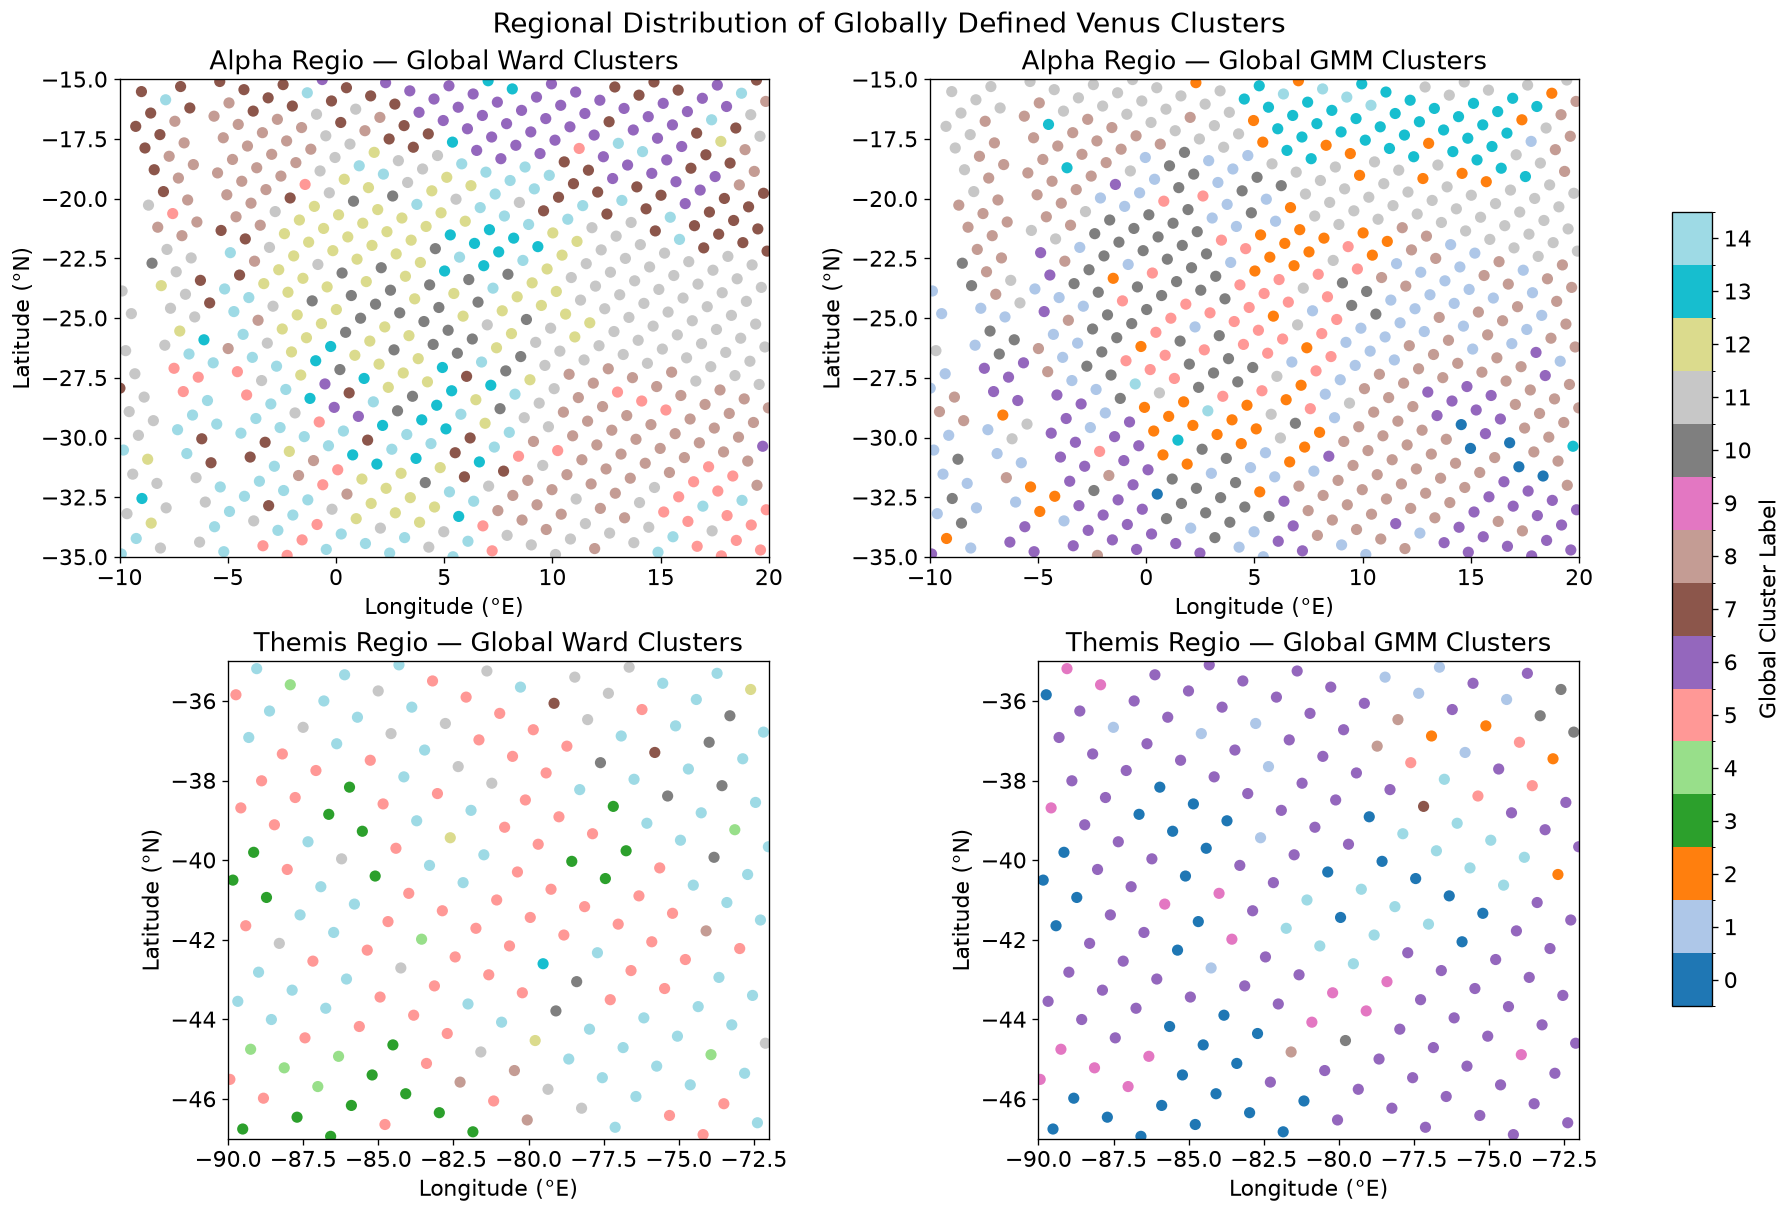

In [48]:
# Cell 15 — Zoom into the global cluster maps

from matplotlib.colors import BoundaryNorm

methods = [
    ("Ward", "Ward_Cluster"),
    ("GMM", "GMM_Cluster")
]

cmap = plt.get_cmap("tab20", K)
norm = BoundaryNorm(np.arange(K + 1) - 0.5, K)

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 10),
    constrained_layout=True
)

for i, (region_name, bounds) in enumerate(REGIONS.items()):

    df_region = regional_subsets[region_name]

    for j, (method_name, cluster_column) in enumerate(methods):

        ax = axes[i, j]

        sc = ax.scatter(
            df_region["Longitude"],
            df_region["Latitude"],
            c=df_region[cluster_column],
            cmap=cmap,
            norm=norm,
            s=45,
            edgecolors="none"
        )

        ax.set_xlim(
            bounds["lon_min"],
            bounds["lon_max"]
        )

        ax.set_ylim(
            bounds["lat_min"],
            bounds["lat_max"]
        )

        central_lat = (
            bounds["lat_min"] + bounds["lat_max"]
        ) / 2

        ax.set_aspect(
            1 / np.cos(np.deg2rad(central_lat))
        )

        ax.set_title(
            f"{region_name} — Global {method_name} Clusters"
        )

        ax.set_xlabel("Longitude (°E)")
        ax.set_ylabel("Latitude (°N)")

fig.colorbar(
    sc,
    ax=axes,
    ticks=np.arange(K),
    label="Global Cluster Label",
    shrink=0.75
)

plt.suptitle(
    "Regional Distribution of Globally Defined Venus Clusters",
    fontsize=17
)

plt.show()